# EAPS 507 — Pandas for Earth Science Data Manipulation
## A 2-hour guided in-class tutorial using Indiana geographic features

**Dataset:** `IN_Features_20140204.txt`

### Learning objectives
By the end of this activity, you should be able to:

1. load a non-comma-delimited text file with `pandas`;
2. inspect a `DataFrame` and diagnose its structure;
3. select columns and filter observations with Boolean conditions;
4. identify and handle missing values deliberately;
5. summarize categorical and numerical data;
6. use `groupby()` and `agg()` to answer scientific questions;
7. sort data and create derived variables;
8. convert text dates into datetime objects; and
9. combine several Pandas operations to answer a question you formulate yourself.

### How this notebook works
This is **not** a copy-and-paste exercise. Each section follows the same cycle:

> **Explain → instructor example → predict/test → your turn → interpret**

Some cells are complete. Others contain blanks (`...`) for you to complete. Before running a **Predict first** cell, write down what you expect to happen.

**Suggested pace:** Sections 1–3 (45 min), Sections 4–6 (45 min), Sections 7–8 + final challenge (30 min).

## 0. Setup and the dataset — about 5 minutes

The file contains named geographic features and attributes such as feature class, state, county, latitude/longitude, elevation, map name, and dates. It is a **pipe-delimited** text file, so fields are separated by `|` rather than commas.

The goal today is not to memorize Pandas syntax. The goal is to learn how to move from a **data question** to an appropriate sequence of Pandas operations.

In [1]:
import pandas as pd

# This option makes wide tables easier to inspect in Jupyter.
pd.set_option("display.max_columns", 25)

In [2]:
# read_csv() can read many delimited text files, not only .csv files.
# sep="|" tells Pandas that the vertical bar separates the columns.

df = pd.read_csv("IN_Features_20140204.txt", sep="|")

df.head()

,FEATURE_ID,FEATURE_NAME,FEATURE_CLASS,STATE_ALPHA,STATE_NUMERIC,COUNTY_NAME,COUNTY_NUMERIC,PRIMARY_LAT_DMS,PRIM_LONG_DMS,PRIM_LAT_DEC,PRIM_LONG_DEC,SOURCE_LAT_DMS,SOURCE_LONG_DMS,SOURCE_LAT_DEC,SOURCE_LONG_DEC,ELEV_IN_M,ELEV_IN_FT,MAP_NAME,DATE_CREATED,DATE_EDITED
0,403294,Brouilletts Creek,Stream,IN,18,Whitley,183,393617N,0872305W,39.604762,-87.384782,393919N,0874800W,39.655230,-87.799900,144.0,472.0,New Goshen,01/15/1980,11/19/2010
1,404056,Beaver Creek,Stream,IL,17,Iroquois,75,405811N,0874850W,40.969755,-87.813927,410159N,0872342W,41.033090,-87.395030,186.0,610.0,L'Erable,01/15/1980,NaN
2,406202,Clear Creek,Stream,IL,17,Edgar,45,392645N,0873001W,39.445869,-87.500300,393514N,0874118W,39.587257,-87.688360,146.0,479.0,Dennison,01/15/1980,NaN
3,406288,Coal Creek,Stream,IL,17,Edgar,45,393829N,0873006W,39.641425,-87.501687,393855N,0873750W,39.648646,-87.630580,151.0,495.0,Saint Bernice,01/15/1980,NaN
4,406345,Cole Creek,Stream,IL,17,Iroquois,75,403756N,0873331W,40.632259,-87.558636,403756N,0873331W,40.632259,-87.558636,207.0,679.0,Darrow,01/15/1980,NaN


### Student-led test 0
Without running another command yet, inspect the first five rows above.

1. Name **two categorical** variables.
2. Name **two numerical** variables.
3. Identify one variable that appears to contain missing values.
4. Why would `pd.read_csv(..., sep="|")` work even though the filename ends in `.txt`?

Discuss your answers with a neighbor for 2 minutes.

**My answers:** (1) `FEATURE_CLASS` and `STATE_ALPHA` are categorical. (2) `PRIM_LAT_DEC` and `ELEV_IN_M` are numerical. (3) `SOURCE_LAT_DEC` has blanks in the initial records. (4) `read_csv()` can parse text files with delimiters regardless of extension; `sep="|"` specifies the actual separator.

---
## 1. Inspecting a DataFrame — about 15 minutes

Before manipulating a dataset, learn its structure.

Useful attributes/methods:

- `df.head()` — first rows
- `df.tail()` — last rows
- `df.shape` — `(number of rows, number of columns)`
- `df.columns` — column labels
- `df.dtypes` — inferred data type of each column
- `df.info()` — compact summary including non-null counts and data types

Notice that `shape`, `columns`, and `dtypes` are **attributes**, while `head()` and `info()` are **methods**.

In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Shape: (29536, 20)

Column names:
['FEATURE_ID', 'FEATURE_NAME', 'FEATURE_CLASS', 'STATE_ALPHA', 'STATE_NUMERIC', 'COUNTY_NAME', 'COUNTY_NUMERIC', 'PRIMARY_LAT_DMS', 'PRIM_LONG_DMS', 'PRIM_LAT_DEC', 'PRIM_LONG_DEC', 'SOURCE_LAT_DMS', 'SOURCE_LONG_DMS', 'SOURCE_LAT_DEC', 'SOURCE_LONG_DEC', 'ELEV_IN_M', 'ELEV_IN_FT', 'MAP_NAME', 'DATE_CREATED', 'DATE_EDITED']


### Predict first
What do you expect Pandas to report for `ELEV_IN_M`, `FEATURE_NAME`, and `DATE_CREATED`?

Write your prediction before running the next cell.

**Prediction:** `ELEV_IN_M` will be numeric (`float64` if missing values are present); `FEATURE_NAME` will be `object` (text); and `DATE_CREATED` will initially be `object` because dates were not parsed during import.

In [4]:
df[["ELEV_IN_M", "FEATURE_NAME", "DATE_CREATED"]].dtypes

ELEV_IN_M       float64
FEATURE_NAME     object
DATE_CREATED     object
dtype: object

### Why is `DATE_CREATED` not automatically a date?
Pandas reads many text fields as `object` unless we explicitly tell it how to interpret them. Later, we will convert the date columns.

### Student-led test 1
Complete the cells below. Do not ask the instructor for the answer until you have tried the documentation/help system or discussed it with a neighbor.

In [5]:
# TEST 1A: tail(n) displays the final n records, rather than the first ones.
df.tail(7)

,FEATURE_ID,FEATURE_NAME,FEATURE_CLASS,STATE_ALPHA,STATE_NUMERIC,COUNTY_NAME,COUNTY_NUMERIC,PRIMARY_LAT_DMS,PRIM_LONG_DMS,PRIM_LAT_DEC,PRIM_LONG_DEC,SOURCE_LAT_DMS,SOURCE_LONG_DMS,SOURCE_LAT_DEC,SOURCE_LONG_DEC,ELEV_IN_M,ELEV_IN_FT,MAP_NAME,DATE_CREATED,DATE_EDITED
29529,2743558,Upland Community Church,Church,IN,18,Grant,53,402756N,0853000W,40.465491,-85.499956,NaN,NaN,NaN,NaN,282.0,925.0,Hartford City West,12/26/2012,NaN
29530,2743605,John T. Myers Lock and Dam,Dam,KY,21,Union,225,374734N,0875929W,37.792778,-87.991390,NaN,NaN,NaN,NaN,99.0,325.0,Uniontown,12/28/2012,09/18/2013
29531,2745826,Kessinger Cemetery,Cemetery,IN,18,Henry,65,395757N,0851504W,39.965938,-85.251160,NaN,NaN,NaN,NaN,341.0,1119.0,New Castle East,03/10/2013,NaN
29532,2748942,Rising Hope Baptist Church,Church,IN,18,Brown,13,391223N,0861329W,39.206422,-86.224714,NaN,NaN,NaN,NaN,213.0,699.0,Nashville,07/16/2013,NaN
29533,2749894,Columbus City Cemetery,Cemetery,IN,18,Bartholomew,5,391256N,0855458W,39.215610,-85.916000,NaN,NaN,NaN,NaN,192.0,630.0,Columbus,09/03/2013,NaN
29534,2760566,Meadows Glen,Populated Place,IN,18,Hamilton,57,400407N,0855913W,40.068638,-85.986989,NaN,NaN,NaN,NaN,241.0,791.0,Riverwood,01/29/2014,NaN
29535,2760567,Meadows Knoll,Populated Place,IN,18,Hamilton,57,400416N,0855850W,40.070979,-85.980434,NaN,NaN,NaN,NaN,242.0,794.0,Riverwood,01/29/2014,NaN


In [6]:
# TEST 1B: info() reports non-null counts and the dtype of every column.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29536 entries, 0 to 29535
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   FEATURE_ID       29536 non-null  int64  
 1   FEATURE_NAME     29536 non-null  object 
 2   FEATURE_CLASS    29536 non-null  object 
 3   STATE_ALPHA      29536 non-null  object 
 4   STATE_NUMERIC    29536 non-null  int64  
 5   COUNTY_NAME      29536 non-null  object 
 6   COUNTY_NUMERIC   29536 non-null  int64  
 7   PRIMARY_LAT_DMS  29536 non-null  object 
 8   PRIM_LONG_DMS    29536 non-null  object 
 9   PRIM_LAT_DEC     29536 non-null  float64
 10  PRIM_LONG_DEC    29536 non-null  float64
 11  SOURCE_LAT_DMS   3838 non-null   object 
 12  SOURCE_LONG_DMS  3838 non-null   object 
 13  SOURCE_LAT_DEC   3838 non-null   float64
 14  SOURCE_LONG_DEC  3838 non-null   float64
 15  ELEV_IN_M        29498 non-null  float64
 16  ELEV_IN_FT       29498 non-null  float64
 17  MAP_NAME    

**Interpretation:** Which columns immediately look like they may require special handling? Why?

**My interpretation:** Source latitude/longitude and edited-date fields contain many missing observations, and date columns need explicit datetime parsing before date operations. Numeric elevations should also be checked for `NaN` before summary statistics.

---
## 2. Selecting columns and rows — about 15 minutes

A DataFrame is two-dimensional. We often need only part of it.

### Selecting one column
`df["COLUMN"]` returns a Pandas `Series`.

### Selecting several columns
Pass a **list of column names**: `df[["A", "B"]]`.

### `.loc[]`
`.loc[rows, columns]` is a flexible label-based selector.

In [7]:
# One column -> Series
feature_names = df["FEATURE_NAME"]
print(type(feature_names))
feature_names.head()

<class 'pandas.core.series.Series'>


0    Brouilletts Creek
1         Beaver Creek
2          Clear Creek
3           Coal Creek
4           Cole Creek
Name: FEATURE_NAME, dtype: object

In [8]:
# Several columns -> DataFrame
location = df[["FEATURE_NAME", "COUNTY_NAME", "PRIM_LAT_DEC", "PRIM_LONG_DEC"]]
location.head()

,FEATURE_NAME,COUNTY_NAME,PRIM_LAT_DEC,PRIM_LONG_DEC
0,Brouilletts Creek,Whitley,39.604762,-87.384782
1,Beaver Creek,Iroquois,40.969755,-87.813927
2,Clear Creek,Edgar,39.445869,-87.500300
3,Coal Creek,Edgar,39.641425,-87.501687
4,Cole Creek,Iroquois,40.632259,-87.558636


In [9]:
# .loc[row selection, column selection]
# Here ':' means all rows.
df.loc[:, ["FEATURE_NAME", "FEATURE_CLASS", "ELEV_IN_M"]].head()

,FEATURE_NAME,FEATURE_CLASS,ELEV_IN_M
0,Brouilletts Creek,Stream,144.0
1,Beaver Creek,Stream,186.0
2,Clear Creek,Stream,146.0
3,Coal Creek,Stream,151.0
4,Cole Creek,Stream,207.0


### Student-led test 2
Create a DataFrame named `geo` containing only:

`FEATURE_NAME`, `FEATURE_CLASS`, `COUNTY_NAME`, `PRIM_LAT_DEC`, `PRIM_LONG_DEC`, and `ELEV_IN_M`.

Then display rows 10 through 15 using `.loc[]`.

**Test yourself:** Is the end label included when using `.loc[10:15]`? Determine this from your output rather than guessing.

**My answer:** Yes. Label-based `.loc[10:15]` includes both label 10 and label 15.

In [10]:
# TEST 2: Select the six geographic attributes needed for later analyses.
columns_needed = [
    "FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME",
    "PRIM_LAT_DEC", "PRIM_LONG_DEC", "ELEV_IN_M"
]
geo = df[columns_needed].copy()

# .loc uses inclusive endpoint labels, so this includes row index 15.
geo.loc[10:15]

,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,PRIM_LAT_DEC,PRIM_LONG_DEC,ELEV_IN_M
10,Grand Calumet River,Stream,Cook,41.643924,-87.560878,177.0
11,Hawks Creek,Stream,Clark,39.383648,-87.516689,136.0
12,Hooper Branch,Stream,Iroquois,40.966700,-87.602811,192.0
13,Iroquois River,Stream,Kankakee,41.074199,-87.816429,181.0
14,Jonathan Creek,Stream,Edgar,39.866981,-87.500018,173.0
15,Jordan Creek,Stream,Vermilion,40.336148,-87.623077,197.0


---
## 3. Boolean filtering — about 20 minutes

Filtering asks Pandas to keep only rows satisfying a condition.

For example, `df["FEATURE_CLASS"] == "Stream"` does **not** immediately return streams. It first produces a Boolean Series of `True` and `False` values. That Boolean mask can then be used to select rows.

In [11]:
is_stream = df["FEATURE_CLASS"] == "Stream"
is_stream.head(10)

0     True
1     True
2     True
3     True
4     True
5    False
6     True
7     True
8     True
9     True
Name: FEATURE_CLASS, dtype: bool

In [12]:
streams = df[is_stream]
streams[["FEATURE_NAME", "COUNTY_NAME", "ELEV_IN_M"]].head()

,FEATURE_NAME,COUNTY_NAME,ELEV_IN_M
0,Brouilletts Creek,Whitley,144.0
1,Beaver Creek,Iroquois,186.0
2,Clear Creek,Edgar,146.0
3,Coal Creek,Edgar,151.0
4,Cole Creek,Iroquois,207.0


### Predict first
What will the expression below return: a number, a Series, or a DataFrame?

```python
(df["ELEV_IN_M"] > 300)
```

Make your prediction, then test it.

**Prediction:** A Boolean **Series** with one `True`/`False` per record (with missing elevations generally evaluating as `False` for `> 300`).

In [13]:
df["ELEV_IN_M"] > 300

0        False
1        False
2        False
3        False
4        False
         ...  
29531     True
29532    False
29533    False
29534    False
29535    False
Name: ELEV_IN_M, Length: 29536, dtype: bool

### Combining conditions
Use:

- `&` for AND
- `|` for OR
- `~` for NOT
- `.isin([...])` when matching several allowed values

Put each condition in parentheses.

In [14]:
# Indiana streams above 250 m
high_in_streams = df[
    (df["STATE_ALPHA"] == "IN") &
    (df["FEATURE_CLASS"] == "Stream") &
    (df["ELEV_IN_M"] > 250)
]

high_in_streams[["FEATURE_NAME", "COUNTY_NAME", "ELEV_IN_M"]].head()

,FEATURE_NAME,COUNTY_NAME,ELEV_IN_M
131,Alexandria Creek,Madison,258.0
202,Amity Branch,Hancock,253.0
210,Ams Run,Hamilton,253.0
237,Andy Run,Madison,263.0
255,Anthony Creek,Hancock,283.0


In [15]:
# isin() is cleaner than writing many OR statements.
water_features = df[df["FEATURE_CLASS"].isin(["Stream", "Lake", "Reservoir", "Canal"])]
water_features.head()

,FEATURE_ID,FEATURE_NAME,FEATURE_CLASS,STATE_ALPHA,STATE_NUMERIC,COUNTY_NAME,COUNTY_NUMERIC,PRIMARY_LAT_DMS,PRIM_LONG_DMS,PRIM_LAT_DEC,PRIM_LONG_DEC,SOURCE_LAT_DMS,SOURCE_LONG_DMS,SOURCE_LAT_DEC,SOURCE_LONG_DEC,ELEV_IN_M,ELEV_IN_FT,MAP_NAME,DATE_CREATED,DATE_EDITED
0,403294,Brouilletts Creek,Stream,IN,18,Whitley,183,393617N,0872305W,39.604762,-87.384782,393919N,0874800W,39.655230,-87.799900,144.0,472.0,New Goshen,01/15/1980,11/19/2010
1,404056,Beaver Creek,Stream,IL,17,Iroquois,75,405811N,0874850W,40.969755,-87.813927,410159N,0872342W,41.033090,-87.395030,186.0,610.0,L'Erable,01/15/1980,NaN
2,406202,Clear Creek,Stream,IL,17,Edgar,45,392645N,0873001W,39.445869,-87.500300,393514N,0874118W,39.587257,-87.688360,146.0,479.0,Dennison,01/15/1980,NaN
3,406288,Coal Creek,Stream,IL,17,Edgar,45,393829N,0873006W,39.641425,-87.501687,393855N,0873750W,39.648646,-87.630580,151.0,495.0,Saint Bernice,01/15/1980,NaN
4,406345,Cole Creek,Stream,IL,17,Iroquois,75,403756N,0873331W,40.632259,-87.558636,403756N,0873331W,40.632259,-87.558636,207.0,679.0,Darrow,01/15/1980,NaN


### Student-led test 3A — basic filtering
Create `lakes` containing only records whose `FEATURE_CLASS` is `"Lake"`.

Then determine how many rows it contains. **Do not use a number supplied by the instructor. Let the data answer the question.**

In [16]:
# TEST 3A: The Boolean mask is True only for features classified as Lake.
lakes = df[df["FEATURE_CLASS"] == "Lake"]

# Count the matching records rather than inserting an assumed answer.
print("Number of Lake records:", len(lakes))

Number of Lake records: 803


### Student-led test 3B — combine conditions
Find all records that:

1. are in Indiana,
2. are either `Lake` or `Reservoir`, and
3. have elevation greater than 250 m.

Store the result as `high_water`. Display only feature name, class, county, and elevation.

In [17]:
# TEST 3B: All three criteria must be true for a row to be retained.
# isin() permits either feature class without multiple OR expressions.
high_water = df[
    (df["STATE_ALPHA"] == "IN") &
    (df["FEATURE_CLASS"].isin(["Lake", "Reservoir"])) &
    (df["ELEV_IN_M"] > 250)
]

# Display only the requested descriptive attributes.
high_water[["FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME", "ELEV_IN_M"]]

,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,ELEV_IN_M
76,Adams Lake,Lake,LaGrange,289.0
154,Allen Lake,Lake,Kosciusko,266.0
246,Lake Anne,Lake,Steuben,316.0
290,Appleman Lake,Lake,LaGrange,295.0
396,Atwood Lake,Lake,LaGrange,273.0
...,...,...,...,...
24069,Clouse Lake,Lake,Noble,273.0
24190,Bell Lake,Lake,Johnson,251.0
25455,Lake Ullswater,Reservoir,Hamilton,273.0
25456,Lake Windemere,Reservoir,Hamilton,273.0


### Check your reasoning
Explain why this expression can be dangerous:

```python
df["FEATURE_CLASS"] == "Lake" | df["FEATURE_CLASS"] == "Reservoir"
```

What role do parentheses play when combining Pandas Boolean conditions?

**My reasoning:** Without parentheses, Python can evaluate the bitwise OR expression before the intended equality comparisons, leading to invalid operations or an incorrect expression. Writing `(df["FEATURE_CLASS"] == "Lake") | (df["FEATURE_CLASS"] == "Reservoir")` makes each comparison a Boolean Series before joining them with `|`.

---
## 4. Missing data — about 15 minutes

Real Earth-science datasets are rarely complete.

Useful tools:

- `.isna()` — identify missing values
- `.notna()` — identify non-missing values
- `.isna().sum()` — count missing values by column
- `.dropna()` — remove observations with missing values
- `.fillna()` — replace missing values

**Important:** missing-data treatment should follow the scientific question. Do not automatically drop every row containing any missing value.

In [18]:
missing = df.isna().sum()
missing.sort_values(ascending=False)

SOURCE_LONG_DMS    25698
SOURCE_LAT_DEC     25698
SOURCE_LONG_DEC    25698
SOURCE_LAT_DMS     25698
DATE_EDITED        23299
ELEV_IN_M             38
ELEV_IN_FT            38
FEATURE_ID             0
STATE_ALPHA            0
FEATURE_CLASS          0
FEATURE_NAME           0
STATE_NUMERIC          0
PRIM_LONG_DEC          0
PRIM_LAT_DEC           0
PRIM_LONG_DMS          0
PRIMARY_LAT_DMS        0
COUNTY_NAME            0
COUNTY_NUMERIC         0
MAP_NAME               0
DATE_CREATED           0
dtype: int64

### Predict first
Consider:

```python
df.dropna()
```

Would you expect this to retain most of the dataset or remove a large fraction? Use the missing-value summary above to justify your prediction **before** running it.

**Prediction:** `df.dropna()` will remove a large fraction of rows because it discards a record if *any* column is missing. Source coordinate and edited-date columns have many blanks, even if elevation and primary coordinates are available.

In [19]:
# Now test the prediction.
print("Original rows:", len(df))
print("Rows after dropna() on ALL columns:", len(df.dropna()))

Original rows: 29536
Rows after dropna() on ALL columns: 125


In [20]:
# A targeted approach: require elevation only.
elevation_data = df.dropna(subset=["ELEV_IN_M"])

print("Original rows:", len(df))
print("Rows with elevation:", len(elevation_data))
print("Rows removed:", len(df) - len(elevation_data))

Original rows: 29536
Rows with elevation: 29498
Rows removed: 38


### Student-led test 4
Calculate the **percentage** of records with missing source latitude (`SOURCE_LAT_DEC`).

You know that a Boolean Series behaves like 1 for `True` and 0 for `False` when averaged. Try to use that idea.

Then answer: would filling missing source latitude with `0` be scientifically sensible? Why or why not?

**My explanation:** No. Zero degrees latitude is a real position on the equator; replacing unknown latitude with 0 would create fictitious locations and distort the spatial analysis. Retaining `NaN` or filtering only when coordinates are required is more defensible.

In [21]:
# TEST 4: isna() produces True for missing values, and mean() gives
# the fraction missing because True counts as 1 and False as 0.
missing_source_pct = df["SOURCE_LAT_DEC"].isna().mean() * 100
print(f"Missing source latitude: {missing_source_pct:.1f}%")

Missing source latitude: 87.0%


---
## 5. Counting, grouping, and aggregation — about 25 minutes

This is where Pandas becomes especially useful for scientific analysis.

### `value_counts()`
Use this when you want frequencies of unique categories.

In [22]:
df["FEATURE_CLASS"].value_counts().head(10)

FEATURE_CLASS
Populated Place    3670
Cemetery           3627
Stream             3542
Church             3275
Canal              2535
School             2425
Building           2006
Civil              1673
Locale              970
Park                865
Name: count, dtype: int64

### Student-led test 5A
Which five counties contain the largest number of records **for Indiana records only**?

You have already used filtering and `value_counts()`. Combine them.

In [23]:
# TEST 5A: First restrict to Indiana, then count records by county.
indiana = df[df["STATE_ALPHA"] == "IN"]

# value_counts() sorts from most to least frequent by default.
top_counties = indiana["COUNTY_NAME"].value_counts().head(5)
top_counties

COUNTY_NAME
Marion      2036
Lake        1463
Hamilton     721
Allen        651
Porter       580
Name: count, dtype: int64

### `groupby()`
Conceptually, `groupby()` performs **split → apply → combine**:

1. split rows into groups;
2. apply a calculation to each group;
3. combine the group results.

Here we ask: *What is the mean elevation for each county?*

In [24]:
county_elevation = (
    indiana.groupby("COUNTY_NAME")["ELEV_IN_M"]
           .mean()
)

county_elevation.head()

COUNTY_NAME
Adams          251.441558
Allen          240.839506
Bartholomew    204.750903
Benton         230.568807
Blackford      271.658120
Name: ELEV_IN_M, dtype: float64

### Predict first
What does each row in `county_elevation` represent?

Now predict what changing `.mean()` to `.max()` would mean scientifically.

**My prediction:** Every row is one county, and the value is the mean of non-missing recorded feature elevations within that county. Replacing `.mean()` with `.max()` returns the greatest recorded elevation per county, not its average terrain height.

In [25]:
indiana.groupby("COUNTY_NAME")["ELEV_IN_M"].max().head()

COUNTY_NAME
Adams          279.0
Allen          302.0
Bartholomew    309.0
Benton         252.0
Blackford      286.0
Name: ELEV_IN_M, dtype: float64

### `agg()` — several summaries at once
`agg()` lets us apply multiple summary functions to each group.

In [26]:
feature_elevation = (
    indiana.groupby("FEATURE_CLASS")["ELEV_IN_M"]
           .agg(["count", "mean", "median", "min", "max"])
)

feature_elevation.head(10)

,count,mean,median,min,max
FEATURE_CLASS,,,,,
Airport,585,233.323077,242.0,113.0,348.0
Arch,4,184.500000,189.5,153.0,206.0
Area,2,186.500000,186.5,133.0,240.0
Bar,5,146.800000,141.0,116.0,175.0
Basin,12,165.500000,148.0,130.0,209.0
Bay,11,215.727273,197.0,175.0,273.0
Beach,3,211.000000,218.0,179.0,236.0
Bend,29,162.655172,153.0,109.0,246.0
Bridge,111,182.315315,173.0,107.0,292.0


### Student-led test 5B
Using `groupby()` and `agg()`, calculate the following elevation statistics **by county**:

- count
- mean
- standard deviation
- minimum
- maximum

Hint: the aggregation name for standard deviation is `"std"`.

In [27]:
# TEST 5B: Split features by county and summarize available elevations.
# count ignores missing elevation values; std is sample standard deviation.
county_stats = (
    indiana.groupby("COUNTY_NAME")["ELEV_IN_M"]
           .agg(["count", "mean", "std", "min", "max"])
)
county_stats.head()

,count,mean,std,min,max
COUNTY_NAME,,,,,
Adams,231,251.441558,7.063366,232.0,279.0
Allen,648,240.839506,10.829243,176.0,302.0
Bartholomew,277,204.750903,20.688670,173.0,309.0
Benton,109,230.568807,10.971653,211.0,252.0
Blackford,117,271.658120,9.651838,204.0,286.0


### Student-led test 5C — make a scientific comparison
Compare elevation statistics for only `Stream`, `Lake`, and `Summit` features.

Do this in two stages:

1. filter the rows;
2. group by `FEATURE_CLASS` and calculate `count`, `mean`, `min`, and `max`.

Which class has the highest mean elevation?

In [28]:
# TEST 5C, step 1: Retain only the three classes being compared.
selected = indiana[indiana["FEATURE_CLASS"].isin(["Stream", "Lake", "Summit"])]

# Step 2: Summarize elevation independently for each feature class.
comparison = (
    selected.groupby("FEATURE_CLASS")["ELEV_IN_M"]
            .agg(["count", "mean", "min", "max"])
)

print("Class with highest mean elevation:", comparison["mean"].idxmax())
comparison

Class with highest mean elevation: Lake


,count,mean,min,max
FEATURE_CLASS,,,,
Lake,794,241.539043,101.0,344.0
Stream,3468,205.638120,99.0,356.0
Summit,298,240.718121,107.0,382.0


---
## 6. Sorting and creating new variables — about 15 minutes

### `sort_values()`
Sorting is often the last step after calculating a quantity.

In [29]:
# Ten highest-elevation Indiana features
highest = (
    indiana.sort_values("ELEV_IN_M", ascending=False)
           [["FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME", "ELEV_IN_M"]]
           .head(10)
)

highest

,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,ELEV_IN_M
24104,Hoosier Hill,Summit,Wayne,382.0
9606,Mount Gilliard Cemetery,Cemetery,Randolph,374.0
2192,Carlos,Populated Place,Randolph,369.0
940,Bethel,Populated Place,Wayne,369.0
6504,Hopewell Church,Church,Wayne,368.0
23282,Township of Greensfork,Civil,Randolph,366.0
1266,Bloomingport,Populated Place,Randolph,363.0
294,Arba,Populated Place,Randolph,363.0
19721,Snow Hill,Populated Place,Randolph,363.0
3181,Crete,Populated Place,Randolph,362.0


### Creating a derived column
Scientific datasets often contain variables from which we calculate new quantities.

This dataset already contains elevation in meters and feet. We can use that redundancy to test a conversion.

In [30]:
# Make a copy before adding experimental/derived columns.
work = indiana.copy()

work["ELEV_FT_CALCULATED"] = work["ELEV_IN_M"] * 3.28084
work["ELEV_FT_DIFFERENCE"] = work["ELEV_IN_FT"] - work["ELEV_FT_CALCULATED"]

work[["ELEV_IN_M", "ELEV_IN_FT", "ELEV_FT_CALCULATED", "ELEV_FT_DIFFERENCE"]].head()

,ELEV_IN_M,ELEV_IN_FT,ELEV_FT_CALCULATED,ELEV_FT_DIFFERENCE
0,144.0,472.0,472.44096,-0.44096
5,241.0,791.0,790.68244,0.31756
20,108.0,354.0,354.33072,-0.33072
27,148.0,486.0,485.56432,0.43568
34,194.0,636.0,636.48296,-0.48296


### Student-led test 6
Use Pandas to answer both questions:

1. What is the largest **absolute** difference between the supplied feet elevation and your calculated value?
2. Why might the difference not be exactly zero?

Hint: a Pandas Series has an `.abs()` method.

**My explanation:** The difference can be nonzero because the stored meter and feet values may have been rounded independently (and the conversion constant has finite precision). A small mismatch therefore does not by itself indicate a bad observation.

In [31]:
# TEST 6: Absolute value removes the sign, so we find the largest
# magnitude of discrepancy between stored and calculated elevations.
max_abs_difference = work["ELEV_FT_DIFFERENCE"].abs().max()
print(f"Largest absolute difference: {max_abs_difference:.4f} ft")

Largest absolute difference: 0.5040 ft


---
## 7. Dates in Pandas — about 10 minutes

`DATE_CREATED` was initially read as text. To perform date-aware operations, convert it with `pd.to_datetime()`.

`errors="coerce"` means values that cannot be interpreted as dates become `NaT` (Not-a-Time) rather than stopping the program.

In [32]:
work["DATE_CREATED"] = pd.to_datetime(work["DATE_CREATED"], errors="coerce")
work["DATE_EDITED"] = pd.to_datetime(work["DATE_EDITED"], errors="coerce")

work[["DATE_CREATED", "DATE_EDITED"]].dtypes

DATE_CREATED    datetime64[ns]
DATE_EDITED     datetime64[ns]
dtype: object

In [33]:
# The .dt accessor exposes datetime components.
work["YEAR_CREATED"] = work["DATE_CREATED"].dt.year

work[["FEATURE_NAME", "DATE_CREATED", "YEAR_CREATED"]].head()

,FEATURE_NAME,DATE_CREATED,YEAR_CREATED
0,Brouilletts Creek,1980-01-15,1980
5,Concordia Theological Seminary,1980-01-15,1980
20,Lost Lake,1980-01-15,1980
27,Spring Creek,1979-02-14,1979
34,Singleton Ditch,1999-09-30,1999


### Student-led test 7
Answer these with Pandas:

1. What is the earliest creation date in the dataset?
2. What is the latest creation date?
3. How many records were created in each year?
4. Which creation year has the most records?

For #3, try `value_counts()` on `YEAR_CREATED` and then decide whether sorting by **count** or by **year** better answers the question you are asking.

In [34]:
# TEST 7: min() and max() locate the earliest and latest valid dates.
earliest = work["DATE_CREATED"].min()
latest = work["DATE_CREATED"].max()
print("Earliest:", earliest)
print("Latest:", latest)

# Extracted years are counted and indexed chronologically for readability.
yearly_counts = work["YEAR_CREATED"].value_counts().sort_index()
print("\nRecords by creation year:")
print(yearly_counts.to_string())

# idxmax() identifies the year corresponding to the greatest count.
most_common_year = yearly_counts.idxmax()
print(f"\nMost records created in: {int(most_common_year)} ({int(yearly_counts.max())} records)")

Earliest: 1979-02-14 00:00:00
Latest: 2014-01-29 00:00:00

Records by creation year:
YEAR_CREATED
1979    18199
1980        5
1982     4947
1990        2
1991       84
1992      348
1993      144
1994        7
1995     1017
1996        4
1997        5
1998       22
1999       17
2000        6
2001       15
2002        3
2003        5
2004       11
2005        6
2006      388
2007      914
2008      711
2009       38
2010      349
2011     1649
2012      516
2013        3
2014        2

Most records created in: 1979 (18199 records)


---
# 8. Final challenge — about 20 minutes
## From Pandas syntax to data analysis

Work individually or in pairs. You may use earlier sections of this notebook, but your final code should run from top to bottom.

Using **Indiana records only**, answer the following:

1. What are the five most common feature classes?
2. Which five counties contain the greatest number of features?
3. For `Stream`, `Lake`, and `Summit`, calculate the number of observations and mean, minimum, and maximum elevation.
4. Identify the 10 highest-elevation features and report their name, feature class, county, and elevation.
5. What percentage of records are missing source coordinates?
6. **Develop one additional question that can be answered with this dataset.**

For Question 6, include:

- your question;
- the Pandas operations you chose;
- your result; and
- a 2–3 sentence interpretation.

### Constraint
For at least one question, your solution must combine **three or more Pandas operations** (for example: filter → group → aggregate → sort).

In [35]:
# FINAL CHALLENGE Q1: Count Indiana records in each feature class.
indiana["FEATURE_CLASS"].value_counts().head(5)

FEATURE_CLASS
Populated Place    3667
Cemetery           3627
Stream             3468
Church             3274
Canal              2528
Name: count, dtype: int64

In [36]:
# FINAL CHALLENGE Q2: Count Indiana records by county and take the top five.
indiana["COUNTY_NAME"].value_counts().head(5)

COUNTY_NAME
Marion      2036
Lake        1463
Hamilton     721
Allen        651
Porter       580
Name: count, dtype: int64

In [37]:
# FINAL CHALLENGE Q3: Filter -> group -> aggregate is a three-step
# analysis: choose classes, compare elevations within each class.
(
    indiana[indiana["FEATURE_CLASS"].isin(["Stream", "Lake", "Summit"])]
    .groupby("FEATURE_CLASS")["ELEV_IN_M"]
    .agg(["count", "mean", "min", "max"])
)

,count,mean,min,max
FEATURE_CLASS,,,,
Lake,794,241.539043,101.0,344.0
Stream,3468,205.638120,99.0,356.0
Summit,298,240.718121,107.0,382.0


In [38]:
# FINAL CHALLENGE Q4: Sort by elevation descending, then display the
# top ten records with the four attributes requested by the assignment.
(
    indiana.sort_values("ELEV_IN_M", ascending=False)
    [["FEATURE_NAME", "FEATURE_CLASS", "COUNTY_NAME", "ELEV_IN_M"]]
    .head(10)
)

,FEATURE_NAME,FEATURE_CLASS,COUNTY_NAME,ELEV_IN_M
24104,Hoosier Hill,Summit,Wayne,382.0
9606,Mount Gilliard Cemetery,Cemetery,Randolph,374.0
2192,Carlos,Populated Place,Randolph,369.0
940,Bethel,Populated Place,Wayne,369.0
6504,Hopewell Church,Church,Wayne,368.0
23282,Township of Greensfork,Civil,Randolph,366.0
1266,Bloomingport,Populated Place,Randolph,363.0
294,Arba,Populated Place,Randolph,363.0
19721,Snow Hill,Populated Place,Randolph,363.0
3181,Crete,Populated Place,Randolph,362.0


In [39]:
# FINAL CHALLENGE Q5: I define "missing source coordinates" as a
# record with either SOURCE_LAT_DEC or SOURCE_LONG_DEC missing. A usable
# coordinate pair needs BOTH latitude and longitude.
missing_pair = indiana[["SOURCE_LAT_DEC", "SOURCE_LONG_DEC"]].isna().any(axis=1)
missing_pair_pct = missing_pair.mean() * 100
print(f"Indiana records with missing source coordinates: {missing_pair_pct:.2f}%")
print(f"Missing at least one coordinate: {missing_pair.sum()} of {len(indiana)}")

Indiana records with missing source coordinates: 87.20%
Missing at least one coordinate: 25653 of 29417


### FINAL CHALLENGE — Question 6: Your own question

**My question:** Among Indiana counties with at least 30 recorded streams that have a valid elevation, which county has the highest average stream elevation?

**Why this question is useful/interesting:** County-level mean stream elevations provide a simple comparison of the topographic settings represented by the catalog. Requiring at least 30 observations helps avoid ranking counties based on only one or two stream records.

**Pandas operations I expect to need:** Boolean filter (`FEATURE_CLASS`), `groupby()`, `agg()`, count threshold filter, `sort_values()`, and `head()`.

In [40]:
# FINAL CHALLENGE Q6: First select Indiana streams that have elevations.
stream_elevations = indiana[
    (indiana["FEATURE_CLASS"] == "Stream") &
    (indiana["ELEV_IN_M"].notna())
]

# Compute each county's number of measured streams and their average height.
stream_county_summary = (
    stream_elevations.groupby("COUNTY_NAME")["ELEV_IN_M"]
                     .agg(["count", "mean"])
)

# Require at least 30 valid elevations, then rank county mean elevations.
eligible_stream_counties = (
    stream_county_summary[stream_county_summary["count"] >= 30]
    .sort_values("mean", ascending=False)
)

print("Highest-ranked county:", eligible_stream_counties.index[0])
print("\nFive highest eligible counties:")
eligible_stream_counties.head(5)

Highest-ranked county: Randolph

Five highest eligible counties:


,count,mean
COUNTY_NAME,,
Randolph,78,321.358974
Wayne,144,305.708333
Henry,120,304.333333
Jay,64,275.062500
Delaware,49,274.897959


**Interpretation (2–3 sentences):** The county at the top of the table has the highest mean elevation among Indiana counties with at least 30 stream records containing usable elevation values. This reflects the distribution of stream features *in this dataset*, not necessarily the true average elevation of every stream reach in each county. The minimum sample-size requirement makes the comparison less sensitive to very small county samples, but it does not eliminate catalog or spatial sampling bias.

---
## Exit ticket — 5 minutes
Answer without copying definitions from above.

1. What is the difference between `value_counts()` and `groupby()`?
2. Why can `dropna()` be dangerous when used without specifying a subset?
3. What does a Boolean mask contain?
4. Write, in words, the sequence of Pandas operations you would use to find the county with the highest mean elevation among streams only.
5. Which Pandas operation from today do you think will be most useful for your own research data, and why?

**My exit-ticket answers:**

1. `value_counts()` tallies occurrences of unique values in a Series; `groupby()` divides records into groups and supports numerical summaries such as mean or maximum for each group.
2. Unrestricted `dropna()` removes an entire row whenever *any* field is missing, even if the missing field is irrelevant to the analysis.
3. A Boolean mask is a sequence of `True`/`False` values indicating which rows satisfy a condition.
4. Filter to streams, group the surviving records by county, calculate mean elevation for each county, sort the means descending, and select the first.
5. `groupby()` with `agg()` would be especially useful for comparing seismic or environmental measurements across stations, sites, or observation periods.

## Optional extension if you finish early
Use `PRIM_LAT_DEC` and `PRIM_LONG_DEC` to make a simple scatter plot of Indiana feature locations. Color or separate the points by one feature class of your choice.

You may use Pandas' built-in `.plot.scatter()` or Matplotlib. This extension is intentionally **not scaffolded**: decide what subset you want to visualize and what question the figure should answer.

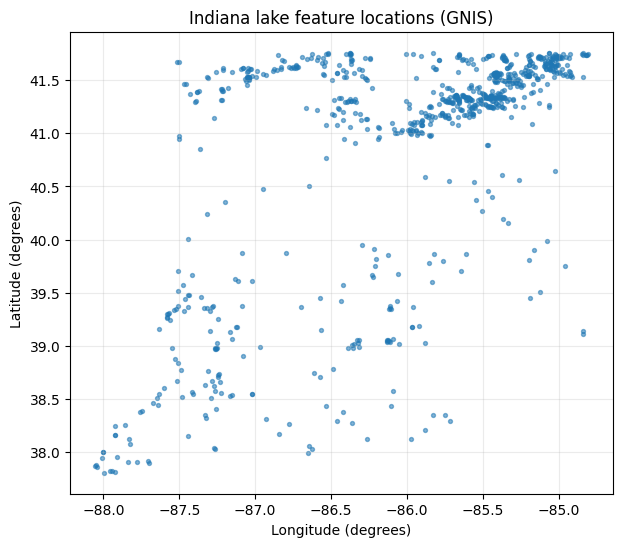

In [41]:
# OPTIONAL EXTENSION: Map Indiana lake feature coordinates to inspect their
# geographic distribution. This plot uses primary coordinates (not source
# coordinates, which have a high missing-data rate).
import matplotlib.pyplot as plt

lake_locations = indiana[
    (indiana["FEATURE_CLASS"] == "Lake") &
    indiana["PRIM_LAT_DEC"].notna() &
    indiana["PRIM_LONG_DEC"].notna()
]
ax = lake_locations.plot.scatter(
    x="PRIM_LONG_DEC", y="PRIM_LAT_DEC", s=8, alpha=0.55, figsize=(7, 6)
)
ax.set_title("Indiana lake feature locations (GNIS)")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.grid(alpha=0.25)
plt.show()